In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

### Photon-subset rebinning: Ontario comparison draft

Discover existing ATL03/ATL08 pairs in your Ontario folder, select a pair, retrieve a small matching photon subset through SlideRule, and compare it with the local HDF5 data. Full remote granules are not saved. This is a feasibility investigation, not yet your full processing pipeline.

Pairs stay together during sorting. Acquisition time, orbit/cycle/region and release must match; file revision numbers may differ. Multiple candidates are reported rather than silently taking the first. Files with a processed_ prefix are supported, but their internal photon indices may have been altered: the comparison reports this rather than assuming equivalence.

Your at_step correction remains available in the legacy adapter. Native ATL03 distance is tested separately. Run cells in order in the same working directory as your Ontario notebook. Live service retrieval has not been validated here.

In [4]:
# %pip install sliderule pandas numpy matplotlib pyproj h5py pyarrow
from pathlib import Path
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import CRS, Transformer

DATA_DIR = Path("../../data_store/ICESat-2/ontario/")
PAIR_INDEX = 5  # Inspect the printed list: safer pairing can change the old index ordering.
LOCAL_ATL03 = None  # Optional explicit Path; set both paths to override discovery.
LOCAL_ATL08 = None
CENTER = None  # Infer from the middle photon of the first requested beam in the LOCAL file.
ROI_HALF_SIZE_M = 2000
BUFFER_M = 300
BEAMS = ["gt1l", "gt1r"]
LENGTHS = [15, 30, 100]
OUTPUT_DIR = Path("../../scratch/icesat2db_rebin_test")
SAVE_PHOTONS = False

# Preserve the current radiometry denominator, including its exact timing definition.
SHOT_COLUMNS = ["delta_time"]
# Alternative sensitivity test: ["pce_mframe_cnt", "ph_id_pulse"].


In [5]:
import re

pattern = re.compile(r"(ATL0[38])_(\d{14})_(\d{8})_(\d{3})_(\d{2}).*\.h5$")
files = [(p, pattern.search(p.name)) for p in sorted(DATA_DIR.glob("*.h5"))]
files = [(p, m) for p, m in files if m]

pairs = []
for p, m in files:
    if m[1] != "ATL03":
        continue
    matches = [
        q for q, n in files
        if n[1] == "ATL08" and n.group(2, 3, 4) == m.group(2, 3, 4)
        and q.name.startswith("processed_") == p.name.startswith("processed_")
    ]
    if len(matches) == 1:
        pairs.append((p, matches[0]))

pairs.sort(key=lambda pair: (pattern.search(pair[0].name).group(2, 3, 4), pair[0].name))
for i, (atl03, atl08) in enumerate(pairs):
    print(f"{i}: {atl03.name} ↔ {atl08.name}")
if not pairs:
    print(f"No unambiguous matching pairs found in {DATA_DIR.resolve()}")

0: ATL03_20181014100103_02410106_007_01_subsetted.h5 ↔ ATL08_20181014100103_02410106_007_01_subsetted.h5
1: ATL03_20181015093524_02560106_007_01_subsetted.h5 ↔ ATL08_20181015093524_02560106_007_01_subsetted.h5
2: ATL03_20181016211934_02790102_007_01_subsetted.h5 ↔ ATL08_20181016211934_02790102_007_01_subsetted.h5
3: ATL03_20181019092703_03170106_007_01_subsetted.h5 ↔ ATL08_20181019092703_03170106_007_01_subsetted.h5
4: ATL03_20181023091845_03780106_007_01_subsetted.h5 ↔ ATL08_20181023091845_03780106_007_01_subsetted.h5
5: ATL03_20181024210256_04010102_007_01_subsetted.h5 ↔ ATL08_20181024210256_04010102_007_01_subsetted.h5
6: ATL03_20181025203717_04160102_007_01_subsetted.h5 ↔ ATL08_20181025203717_04160102_007_01_subsetted.h5
7: ATL03_20181028205437_04620102_007_01_subsetted.h5 ↔ ATL08_20181028205437_04620102_007_01_subsetted.h5
8: ATL03_20181029202857_04770102_007_02_subsetted.h5 ↔ ATL08_20181029202857_04770102_007_02_subsetted.h5
9: ATL03_20181031090209_05000106_007_01_subsetted.h5 ↔ 

In [6]:
import re
import h5py

NAME_PATTERN = re.compile(r"(?P<product>ATL0[38])_(?P<time>\d{14})_(?P<track>\d{8})_(?P<release>\d{3})_(?P<revision>\d{2}).*\.h5$")

def granule_info(path):
    match = NAME_PATTERN.search(Path(path).name)
    if match is None:
        raise ValueError(f"Unrecognised granule filename: {Path(path).name}")
    info = match.groupdict()
    info["resource"] = (
        f"{info['product']}_{info['time']}_{info['track']}_"
        f"{info['release']}_{info['revision']}.h5"
    )  # Remote granule name excludes local prefixes and suffixes.
    return info

def acquisition_key(info):
    return (info["time"], info["track"], info["release"])

def discover_pairs(directory):
    paths = sorted(Path(directory).glob("*.h5"))
    parsed = [(p, granule_info(p)) for p in paths if NAME_PATTERN.search(p.name)]
    pairs, unmatched, ambiguous = [], [], []
    for p03, i03 in parsed:
        if i03["product"] != "ATL03":
            continue
        matches = [p for p, info in parsed if info["product"] == "ATL08"
                   and acquisition_key(info) == acquisition_key(i03)
                   and p.name.startswith("processed_") == p03.name.startswith("processed_")]
        if len(matches) == 1:
            pairs.append((p03, matches[0]))
        elif matches:
            ambiguous.append((p03, matches))
        else:
            unmatched.append(p03)
    pairs.sort(key=lambda pair: (acquisition_key(granule_info(pair[0])), pair[0].name))
    return pairs, unmatched, ambiguous

pairs, unmatched, ambiguous = discover_pairs(DATA_DIR)
for i, (atl03, atl08) in enumerate(pairs):
    print(f"{i}: {atl03.name} ↔ {atl08.name}")
print(f"Valid PAIR_INDEX: 0–{len(pairs)-1}" if pairs else "No unambiguous matching pairs found.")
print("Directory:", DATA_DIR.resolve())
print("Ambiguous candidates:", [(p.name, [q.name for q in matches]) for p, matches in ambiguous])

if (LOCAL_ATL03 is None) != (LOCAL_ATL08 is None):
    raise ValueError("Set both explicit file paths, or leave both as None.")
if LOCAL_ATL03 is None:
    if not 0 <= PAIR_INDEX < len(pairs):
        raise ValueError("Choose PAIR_INDEX from the printed pairs, or set explicit paths.")
    LOCAL_ATL03, LOCAL_ATL08 = pairs[PAIR_INDEX]
LOCAL_ATL03, LOCAL_ATL08 = Path(LOCAL_ATL03), Path(LOCAL_ATL08)
i03, i08 = granule_info(LOCAL_ATL03), granule_info(LOCAL_ATL08)
if i03["product"] != "ATL03" or i08["product"] != "ATL08" or acquisition_key(i03) != acquisition_key(i08):
    raise ValueError("The local pair must match acquisition, orbit/cycle/region and release.")
RESOURCE = i03["resource"]
print("Selected ATL03:", LOCAL_ATL03.resolve())
print("Selected ATL08:", LOCAL_ATL08.resolve())
print("Remote ATL03 resource:", RESOURCE)
print("Expected ATL08 resource:", i08["resource"])

# Request every quality value actually present in the selected local beams.
# This avoids hard-coding release-006 values when testing release 007.
with h5py.File(LOCAL_ATL03, "r") as h:
    missing_beams = [beam for beam in BEAMS if f"{beam}/heights/h_ph" not in h]
    if missing_beams:
        raise ValueError(f"Requested beams absent locally: {missing_beams}; adjust BEAMS.")
    quality_values = set()
    for beam in BEAMS:
        quality_values.update(int(v) for v in np.unique(h[f"{beam}/heights/quality_ph"][:]))
    QUALITY_VALUES = sorted(quality_values)
    if CENTER is None:
        group = h[f"{BEAMS[0]}/heights"]
        mid = len(group["lat_ph"]) // 2
        CENTER = (float(group["lon_ph"][mid]), float(group["lat_ph"][mid]))
print("Analysis centre:", CENTER, "quality values:", QUALITY_VALUES)


0: ATL03_20181014100103_02410106_007_01_subsetted.h5 ↔ ATL08_20181014100103_02410106_007_01_subsetted.h5
1: ATL03_20181015093524_02560106_007_01_subsetted.h5 ↔ ATL08_20181015093524_02560106_007_01_subsetted.h5
2: ATL03_20181016211934_02790102_007_01_subsetted.h5 ↔ ATL08_20181016211934_02790102_007_01_subsetted.h5
3: ATL03_20181019092703_03170106_007_01_subsetted.h5 ↔ ATL08_20181019092703_03170106_007_01_subsetted.h5
4: ATL03_20181023091845_03780106_007_01_subsetted.h5 ↔ ATL08_20181023091845_03780106_007_01_subsetted.h5
5: ATL03_20181024210256_04010102_007_01_subsetted.h5 ↔ ATL08_20181024210256_04010102_007_01_subsetted.h5
6: ATL03_20181025203717_04160102_007_01_subsetted.h5 ↔ ATL08_20181025203717_04160102_007_01_subsetted.h5
7: ATL03_20181028205437_04620102_007_01_subsetted.h5 ↔ ATL08_20181028205437_04620102_007_01_subsetted.h5
8: ATL03_20181029202857_04770102_007_02_subsetted.h5 ↔ ATL08_20181029202857_04770102_007_02_subsetted.h5
9: ATL03_20181031090209_05000106_007_01_subsetted.h5 ↔ 

### Core rebinning

Each granule/beam is processed separately. Bins are left-closed/right-open and anchored at native distance zero, so changing the ROI does not move them. No quality threshold is applied to the resulting rates here. Empty bins have zero counts and NaN rates; absence of returns is not interpreted as zero reflectance. edge_bin and max_photon_gap_m are diagnostics, not proof of complete coverage.

Ground = ATL08 class 1, canopy = 2, top of canopy = 3. Both rates use the union of shots containing any of these classes. Class counts use row counts, as in your uploaded code. A class absent from an otherwise observed bin is explicitly zero (the existing groupby implementation can instead leave NaN).

In [7]:
KEYS = ["resource", "beam"]

def rebin_photons(photons, length, coordinate="x_atc", origin=0.0,
                  units_per_m=1.0, shot_columns=("delta_time",)):
    if length <= 0 or not np.isfinite(units_per_m) or units_per_m <= 0:
        raise ValueError("Length and coordinate scale must be positive.")
    required = KEYS + [coordinate, "classification", "h_ph"] + list(shot_columns)
    missing = set(required) - set(photons.columns)
    if missing:
        raise ValueError(f"Missing photon fields: {sorted(missing)}")
    rows = []
    for key, frame in photons.groupby(KEYS, sort=False):
        f = frame.copy()
        if not np.isfinite(f[coordinate]).all() or f[list(shot_columns)].isna().any().any():
            raise ValueError("Invalid distance or shot identifiers; inspect the input.")
        f["bin_id"] = np.floor((f[coordinate] - origin) / (units_per_m * length)).astype("int64")
        if f.empty:
            continue
        low, high = int(f.bin_id.min()), int(f.bin_id.max())
        if high - low > 1_000_000:
            raise ValueError("Unexpected coordinate range; inspect coordinate scaling.")
        groups = dict(tuple(f.groupby("bin_id")))
        for b in range(low, high + 1):
            g = groups.get(b, f.iloc[:0])
            signal = g[g.classification.isin([1, 2, 3])]
            ground = g[g.classification.eq(1)]
            canopy = g[g.classification.isin([2, 3])]
            shots = len(signal.drop_duplicates(list(shot_columns)))
            ng, nc, nt = [int(g.classification.eq(c).sum()) for c in (1, 2, 3)]
            x = np.sort(g[coordinate].to_numpy() / units_per_m)
            row = dict(zip(KEYS, key))
            row.update(bin_id=b, length_m=length,
                       coordinate_start=origin+b*length*units_per_m,
                       coordinate_end=origin+(b+1)*length*units_per_m,
                       n_te_photons=ng, n_ca_photons=nc, n_toc_photons=nt,
                       n_classed_shots=shots, n_seg_ph=len(g),
                       photon_rate_te=ng/shots if shots else np.nan,
                       photon_rate_can_nr=(nc+nt)/shots if shots else np.nan,
                       edge_bin=b in (low, high), empty_bin=len(g)==0,
                       max_photon_gap_m=np.diff(x).max() if len(x)>1 else np.nan,
                       observed_span_m=np.ptp(x) if len(x) else np.nan,
                       longitude=g.longitude.mean() if "longitude" in g else np.nan,
                       latitude=g.latitude.mean() if "latitude" in g else np.nan,
                       h_te_median=ground.h_ph.median(),
                       h_te_std=ground.h_ph.std(ddof=0),
                       h_mean_canopy_abs=canopy.h_ph.mean())
            for field in ("spot",):
                if field in g and len(g):
                    row[field] = g[field].iloc[0]
            if "norm_h" in g:
                h = canopy.norm_h.where(canopy.norm_h.abs() < 1e30).dropna()
                row["canopy_openness"] = h.std(ddof=0)
                row["canopy_h"] = h.quantile(.98) if len(h) else np.nan
            rows.append(row)
    return pd.DataFrame(rows)


def legacy_rebin(atl03_df, atl08_df, length, resource="local", beam="gt1l",
                 res_field="alongtrack"):
    # Apply Thomas's exact scale correction to existing PhoREAL coordinate columns.
    at03 = np.asarray(atl03_df[res_field], dtype=float)
    at08 = np.asarray(atl08_df[res_field], dtype=float)
    if len(at03) == 0 or len(at08) == 0:
        raise ValueError("Empty input to legacy adapter.")
    if len(at08) > 2:  # Matches the supplied current binner, including its fallback.
        step = np.min(np.abs(np.diff(at08)))
        scale = step / 100.0
    else:
        step, scale = np.nan, 1.0
    f = atl03_df.copy()
    f["resource"], f["beam"] = resource, beam
    f = f.rename(columns={"lon_ph": "longitude", "lat_ph": "latitude"})
    result = rebin_photons(f, length, res_field, np.min(at03), scale)
    # The uploaded binner uses arange(min, max), excluding its final occupied bin.
    result = result[result.bin_id < result.bin_id.max()].copy()
    result["at_step"] = step
    return result


### Small offline checks

These test the scientifically important cases: shared shots across classes, a missing class, empty bins, beam separation, and a coordinate scale inflated by 18.6. They do not validate the remote service.

In [8]:
def offline_checks():
    p = pd.DataFrame(dict(resource=["test"]*5, beam=["gt1l"]*5,
        x_atc=[1., 2., 3., 31., 61.], classification=[1, 2, 3, 1, 0],
        h_ph=[10., 11., 12., 10., 99.], delta_time=[1., 1., 2., 3., 4.]))
    a = rebin_photons(p, 15)
    assert a.loc[0, "n_classed_shots"] == 2
    assert a.loc[0, "photon_rate_te"] == .5
    assert a.loc[0, "photon_rate_can_nr"] == 1
    assert a.loc[1, "empty_bin"] and np.isnan(a.loc[1, "photon_rate_te"])
    assert a.loc[2, "photon_rate_can_nr"] == 0
    assert np.isnan(a.loc[4, "photon_rate_can_nr"])
    doubled = pd.concat([p, p.assign(beam="gt1r")])
    assert len(rebin_photons(doubled, 15)) == 2*len(a)
    p["distorted"] = p.x_atc*18.6
    b = rebin_photons(p, 15, "distorted", units_per_m=18.6)
    pd.testing.assert_series_equal(a.n_te_photons, b.n_te_photons)
    print("Offline scientific checks passed.")
offline_checks()


Offline scientific checks passed.


### Retrieve photons

Use the current SlideRule atl03x photon endpoint. Do not enable phoreal here: the current x-series API documents that it replaces photon columns with aggregate vegetation metrics. Relative canopy heights and all inherited ATL08 flags are therefore deferred in this minimal remote draft. Absolute photon heights and core radiometry are retained.

Every quality value found in the local beams and all confidence classes are explicitly requested. The resource comes from the selected local file, including its release and revision. SlideRule selects the associated ATL08 remotely; its exact revision is not pinned by this request, so local/remote classification differences must be investigated. No YAPC filter is enabled. Requests are separate per resource and beam, so identities cannot collide. The exact original delta_time is requested to avoid relying on a converted datetime index for shot counts.

In [9]:
def region_polygon(center, half_size):
    crs = CRS.from_proj4(f"+proj=aeqd +lat_0={center[1]} +lon_0={center[0]} +datum=WGS84 +units=m")
    reverse = Transformer.from_crs(crs, 4326, always_xy=True)
    corners = [(-half_size,-half_size), (half_size,-half_size),
               (half_size,half_size), (-half_size,half_size), (-half_size,-half_size)]
    # Sample the edges so a large box does not rely on only four transformed corners.
    points = []
    for start, end in zip(corners[:-1], corners[1:]):
        for t in np.linspace(0, 1, 20, endpoint=False):
            lon, lat = reverse.transform(start[0]+t*(end[0]-start[0]), start[1]+t*(end[1]-start[1]))
            points.append(dict(lon=lon, lat=lat))
    points.append(points[0])
    return points, crs

polygon, roi_crs = region_polygon(CENTER, ROI_HALF_SIZE_M + BUFFER_M)

def fetch_photons(resource, beams, polygon):
    from sliderule import sliderule
    sliderule.init(verbose=True, rethrow=True)
    parts, requests = [], []
    for beam in beams:
        parms = dict(poly=polygon, beams=[beam], srt=0,
            cnf=[-2,-1,0,1,2,3,4], quality_ph=QUALITY_VALUES, podppd=255,
            atl08_class=["atl08_noise", "atl08_ground", "atl08_canopy",
                         "atl08_top_of_canopy", "atl08_unclassified"],
            len=100.0, res=100.0, ats=0.0, cnt=1, pass_invalid=True,
            atl03_ph_fields=["delta_time", "h_ph", "pce_mframe_cnt", "ph_id_pulse"])
        requests.append(dict(resource=resource, beam=beam, parameters=parms))
        raw = sliderule.run("atl03x", parms, resources=[resource])
        if raw is None or len(raw) == 0:
            print(f"No photons returned for {beam}.")
            continue
        required = {"ph_index", "x_atc", "atl08_class", "delta_time", "h_ph",
                    "pce_mframe_cnt", "ph_id_pulse"}
        missing = required - set(raw.columns)
        if missing:
            raise ValueError(f"Unexpected service schema; missing {missing}. Returned: {list(raw.columns)}")
        f = pd.DataFrame(raw.drop(columns="geometry", errors="ignore")).copy()
        if "geometry" in raw:
            f["longitude"], f["latitude"] = raw.geometry.x.to_numpy(), raw.geometry.y.to_numpy()
        if not {"longitude", "latitude"}.issubset(f.columns):
            raise ValueError("Service did not return photon locations.")
        f = f.reset_index(drop=True).rename(columns={"atl08_class": "classification"})
        f["resource"], f["beam"] = resource, beam
        # Reject unexpected beam selection rather than mixing beams under one label.
        expected_gt = {"gt1l":10,"gt1r":20,"gt2l":30,"gt2r":40,"gt3l":50,"gt3r":60}[beam]
        if "gt" in f and not f["gt"].isin([expected_gt, beam]).all():
            raise ValueError("Service returned an unexpected beam; inspect request selection.")
        dup = f.duplicated(KEYS+["ph_index"])
        print(beam, len(f), "rows;", int(dup.sum()), "duplicate photon indices removed")
        f = f.drop_duplicates(KEYS+["ph_index"])
        parts.append(f)
    if not parts:
        raise RuntimeError("No photons returned. Check granule availability and ROI; no version fallback was used.")
    return pd.concat(parts, ignore_index=True), requests

photons, request_log = fetch_photons(RESOURCE, BEAMS, polygon)
print(photons.groupby(["beam", "classification"]).size())
print("Shot counts:", photons.groupby("beam").apply(
    lambda f: pd.Series({"delta_time": f.delta_time.nunique(),
                        "frame_pulse": len(f.drop_duplicates(["pce_mframe_cnt", "ph_id_pulse"]))})))


1792674572.247822 INFO     [  session.py: 1027] Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
1792674572.248986 INFO     [  session.py: 1027] (dataframe.lua:138) <AppServer.1656> ATL03_20181024210256_04010102_007_01.h5/gt1l generated 13657 rows and 18 columns
1792674572.250436 INFO     [  session.py: 1027] Successfully completed processing resource [1 out of 1]: ATL03_20181024210256_04010102_007_01.h5
1792674572.251169 INFO     [  session.py: 1027] Successfuly received 13657 x 24 dataframe (eofs=1, dups=0, ptls=0)
1792674572.518274 INFO     [  session.py: 1039] Writing output file: /tmp/tmp_oj4_sb7
1792674573.407315 INFO     [  session.py: 1050] Closing output file: /tmp/tmp_oj4_sb7


gt1l 13657 rows; 0 duplicate photon indices removed


1792674575.590808 INFO     [  session.py: 1027] Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
1792674592.255186 INFO     [  session.py: 1027] (dataframe.lua:138) <AppServer.1708> ATL03_20181024210256_04010102_007_01.h5/gt1r generated 30205 rows and 18 columns
1792674592.256157 INFO     [  session.py: 1027] Successfully completed processing resource [1 out of 1]: ATL03_20181024210256_04010102_007_01.h5
1792674592.257087 INFO     [  session.py: 1027] Successfuly received 30205 x 24 dataframe (eofs=1, dups=0, ptls=0)
1792674592.260561 INFO     [  session.py: 1039] Writing output file: /tmp/tmp0vcjtkyt
1792674593.271849 INFO     [  session.py: 1050] Closing output file: /tmp/tmp0vcjtkyt


gt1r 30205 rows; 0 duplicate photon indices removed
beam  classification
gt1l  0                   919
      1                  4979
      2                  1779
      3                   249
      4                  5731
gt1r  0                  1652
      1                 17174
      2                  5615
      3                   907
      4                  4857
dtype: int64
Shot counts:       delta_time  frame_pulse
beam                         
gt1l        5172         5172
gt1r        6192         6192


/tmp/ipykernel_2417503/2552604097.py:59: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print("Shot counts:", photons.groupby("beam").apply(


n_classed_shots        photon_rate_te            \
                        count median          count    median   
beam length_m                                                   
gt1l 15                   268   10.0            244  1.080128   
     30                   134   19.5            125  1.115385   
     100                   40   67.5             40  1.096427   
gt1r 15                   267   19.0            267  1.450000   
     30                   134   38.5            134  1.595029   
     100                   40  127.5             40  1.825747   

              photon_rate_can_nr            
                           count    median  
beam length_m                               
gt1l 15                      244  0.371711  
     30                      125  0.400000  
     100                      40  0.530146  
gt1r 15                      267  1.117647  
     30                      134  1.152074  
     100                      40  1.185938

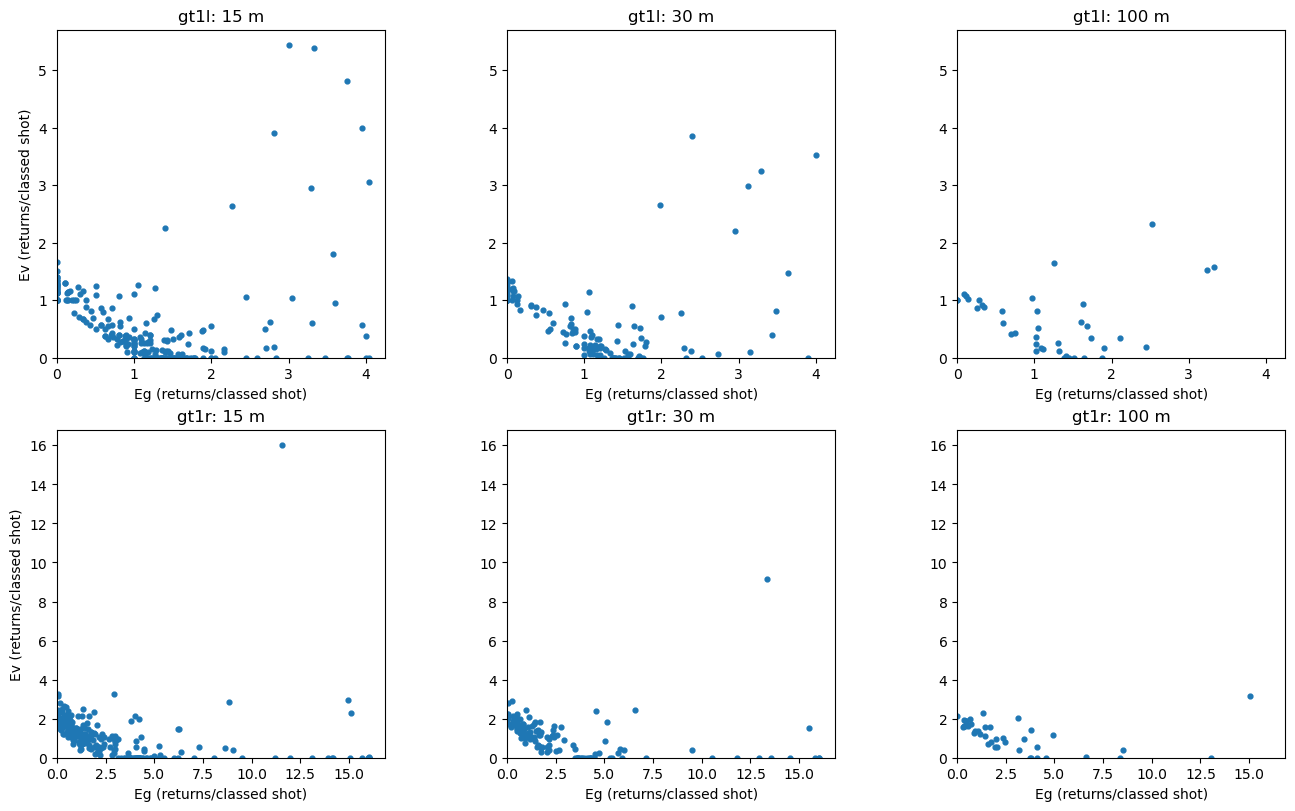

In [12]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

def inside_roi(table):
    project = Transformer.from_crs(4326, roi_crs, always_xy=True)
    x, y = project.transform(
        table.longitude.to_numpy(), table.latitude.to_numpy()
    )
    return (np.abs(x) <= ROI_HALF_SIZE_M) & (np.abs(y) <= ROI_HALF_SIZE_M)


segments = pd.concat(
    [rebin_photons(photons, length, shot_columns=SHOT_COLUMNS)
     for length in LENGTHS],
    ignore_index=True,
)
segments["in_analysis_roi"] = inside_roi(segments)
analysis = segments[
    segments.in_analysis_roi & ~segments.edge_bin
].copy()

display(
    analysis.groupby(["beam", "length_m"])[
        ["n_classed_shots", "photon_rate_te", "photon_rate_can_nr"]
    ].agg(["count", "median"])
)

fig, axes = plt.subplots(
    len(BEAMS), len(LENGTHS),
    figsize=(4.5 * len(LENGTHS), 4 * len(BEAMS)),
    squeeze=False,
    sharex="row",                  # Same Eg scale within each beam.
    sharey="row",                  # Same Ev scale within each beam.
    layout="constrained",
)

cmap = plt.get_cmap("viridis")

for i, beam in enumerate(BEAMS):
    beam_data = analysis[analysis.beam == beam].copy()
    track_start = photons.loc[photons.beam == beam, "x_atc"].min()

    # Native along-track coordinates are metres; use bin midpoints for colour.
    beam_data["alongtrack_km"] = (
        (beam_data.coordinate_start + beam_data.coordinate_end) / 2
        - track_start
    ) / 1000

    valid = np.isfinite(
        beam_data[["photon_rate_te", "photon_rate_can_nr", "alongtrack_km"]]
    ).all(axis=1)
    beam_data = beam_data[valid]

    if not beam_data.empty:
        colour_min = beam_data.alongtrack_km.min()
        colour_max = beam_data.alongtrack_km.max()
        norm = Normalize(
            vmin=colour_min,
            vmax=colour_max if colour_max > colour_min else colour_min + 0.001,
        )

        # Compute limits from all resolutions for this beam.
        xmax = max(beam_data.photon_rate_te.max() * 1.05, 0.1)
        ymax = max(beam_data.photon_rate_can_nr.max() * 1.05, 0.1)

    for j, length in enumerate(LENGTHS):
        ax = axes[i, j]
        t = beam_data[beam_data.length_m == length]

        if not beam_data.empty:
            ax.scatter(
                t.photon_rate_te,
                t.photon_rate_can_nr,
                # c=t.alongtrack_km,
                # cmap=cmap,
                # norm=norm,         # Identical colours mean identical distances.
                s=12,
            )
            ax.set_xlim(0, xmax)
            ax.set_ylim(0, ymax)

        ax.set(
            title=f"{beam}: {length} m",
            xlabel="Eg (returns/classed shot)",
        )
        if j == 0:
            ax.set_ylabel("Ev (returns/classed shot)")
        ax.set_box_aspect(1)
        ax.tick_params(labelbottom=True, labelleft=True)

    # if not beam_data.empty:
    #     fig.colorbar(
    #         ScalarMappable(norm=norm, cmap=cmap),
    #         ax=axes[i, :].tolist(),
    #         label="Along-track distance from first retrieved photon (km)",
    #         shrink=0.85,
    #         pad=0.02,
    #     )

plt.show()

### Optional local-file validation

This independent reader maps ATL08 classes using the original photon indices, and constructs distance as segment_dist_x + dist_ph_along. Only an existing local pair is used. It reads photon arrays one beam at a time; this is a validation path, not the intended production storage workflow.

The comparison reports missing photons as well as differences among shared photons. It does not silently restrict to their intersection and declare success. Photon indices are treated as zero-based; mismatches should be investigated, not automatically shifted. Matching raw timing and height also checks this assumption.

In [15]:
from scipy.spatial import cKDTree

def read_local_pair(path03, path08, beam):
    import h5py
    if granule_info(path03)["resource"] != RESOURCE or acquisition_key(granule_info(path03)) != acquisition_key(granule_info(path08)):
        raise ValueError("Comparison requires the selected acquisition and matching release.")
    with h5py.File(path03, "r") as a, h5py.File(path08, "r") as b:
        h, geo, sig = a[f"{beam}/heights"], a[f"{beam}/geolocation"], b[f"{beam}/signal_photons"]
        N = len(h["h_ph"])
        f = pd.DataFrame({name: h[name][:] for name in
                          ["h_ph", "delta_time", "lat_ph", "lon_ph", "pce_mframe_cnt", "ph_id_pulse"]})
        f = f.rename(columns={"lat_ph":"latitude", "lon_ph":"longitude"})
        f["ph_index"] = np.arange(N)
        starts, counts = geo["ph_index_beg"][:].astype("int64")-1, geo["segment_ph_cnt"][:]
        ids, distances = geo["segment_id"][:], geo["segment_dist_x"][:]
        x = np.full(N, np.nan)
        for start, count, distance in zip(starts, counts, distances):
            if start >= 0 and count > 0:
                x[start:start+count] = distance + h["dist_ph_along"][start:start+count]
        f["x_atc"] = x
        start_map = pd.Series(starts, index=ids)
        mapped_start = pd.Series(sig["ph_segment_id"][:]).map(start_map).to_numpy()
        offsets = sig["classed_pc_indx"][:].astype("int64")-1
        valid = np.isfinite(mapped_start) & (mapped_start >= 0)
        index = (mapped_start[valid] + offsets[valid]).astype("int64")
        if ((index < 0) | (index >= N)).any():
            raise ValueError("Invalid ATL08-to-ATL03 mapping.")
        classes, norm = np.full(N, -1), np.full(N, np.nan)
        classes[index] = sig["classed_pc_flag"][:][valid]
        norm[index] = sig["ph_h"][:][valid]
        norm[np.abs(norm) > 1e30] = np.nan
        f["classification"], f["norm_h"] = classes, norm
        f["resource"], f["beam"] = RESOURCE, beam
    # Match the buffered query polygon, including its edge sampling.
    from shapely.geometry import Polygon
    from shapely import contains_xy
    shape = Polygon([(p["lon"],p["lat"]) for p in polygon])
    return f[contains_xy(shape, f.longitude.to_numpy(), f.latitude.to_numpy())].copy()


from scipy.spatial import cKDTree


def compare_photons(remote, local):
    time_tol = 1e-7       # Seconds.
    height_tol = 0.001    # Metres.
    position_tol = 0.05  # Metres.

    a = remote.reset_index(drop=True).copy()
    b = local.reset_index(drop=True).copy()
    a["classification"] = a.classification.replace(4, -1)

    required = KEYS + [
        "delta_time", "h_ph", "latitude", "longitude", "classification"
    ]
    for label, table in [("remote", a), ("local", b)]:
        missing = set(required) - set(table.columns)
        if missing:
            raise ValueError(f"{label} is missing: {sorted(missing)}")

    matches = []
    diagnostics = []

    def features(table, t0):
        lat = np.radians(table.latitude.to_numpy())
        lon = np.radians(table.longitude.to_numpy())
        radius = 6_371_000.0

        # Cartesian surface coordinates avoid longitude-wrap problems.
        return np.column_stack([
            (table.delta_time.to_numpy() - t0) / time_tol,
            table.h_ph.to_numpy() / height_tol,
            radius * np.cos(lat) * np.cos(lon) / position_tol,
            radius * np.cos(lat) * np.sin(lon) / position_tol,
            radius * np.sin(lat) / position_tol,
        ])

    # Only compare photons within the same source granule and beam.
    all_keys = pd.concat([a[KEYS], b[KEYS]]).drop_duplicates()

    for key in all_keys.itertuples(index=False, name=None):
        remote_mask = np.ones(len(a), dtype=bool)
        local_mask = np.ones(len(b), dtype=bool)
        for field, value in zip(KEYS, key):
            remote_mask &= a[field].eq(value).to_numpy()
            local_mask &= b[field].eq(value).to_numpy()

        ra = a.loc[remote_mask]
        lb = b.loc[local_mask]

        identity_fields = ["delta_time", "h_ph", "latitude", "longitude"]
        ra_valid = ra[
            np.isfinite(ra[identity_fields].to_numpy()).all(axis=1)
        ]
        lb_valid = lb[
            np.isfinite(lb[identity_fields].to_numpy()).all(axis=1)
        ]

        pairs = []
        candidate_count = np.zeros(len(ra_valid), dtype=int)
        local_degree = np.zeros(len(lb_valid), dtype=int)

        if len(ra_valid) and len(lb_valid):
            t0 = min(
                ra_valid.delta_time.min(),
                lb_valid.delta_time.min(),
            )
            rf = features(ra_valid, t0)
            lf = features(lb_valid, t0)

            # Find candidates within the time/height/position tolerances.
            candidates = cKDTree(lf).query_ball_point(
                rf, r=1.0, p=np.inf
            )

            for i, candidate in enumerate(candidates):
                candidate = np.asarray(candidate, dtype=int)
                if len(candidate):
                    spatial_difference = (
                        lf[candidate, 2:] - rf[i, 2:]
                    )
                    horizontal_distance = np.linalg.norm(
                        spatial_difference, axis=1
                    )
                    candidate = candidate[horizontal_distance <= 1.0]

                candidates[i] = candidate
                candidate_count[i] = len(candidate)
                local_degree[candidate] += 1

            # Accept only matches that are unique in both directions.
            for i, candidate in enumerate(candidates):
                if len(candidate) == 1 and local_degree[candidate[0]] == 1:
                    pairs.append((
                        ra_valid.index[i],
                        lb_valid.index[candidate[0]],
                    ))

        matches.extend(pairs)

        diagnostic = dict(zip(KEYS, key))
        diagnostic.update(
            remote_photons=len(ra),
            local_photons=len(lb),
            matched=len(pairs),
            remote_unmatched=len(ra) - len(pairs),
            local_unmatched=len(lb) - len(pairs),
            remote_without_candidate=int((candidate_count == 0).sum()),
            remote_ambiguous=int(
                (candidate_count > 0).sum() - len(pairs)
            ),
            remote_invalid=len(ra) - len(ra_valid),
            local_invalid=len(lb) - len(lb_valid),
        )
        diagnostics.append(diagnostic)

    display(pd.DataFrame(diagnostics))

    remote_indices = [i for i, _ in matches]
    local_indices = [j for _, j in matches]

    matched = pd.concat([
        a.loc[remote_indices].reset_index(drop=True).add_suffix("_remote"),
        b.loc[local_indices].reset_index(drop=True).add_suffix("_local"),
    ], axis=1)

    print("Photon membership:", {
        "remote_only_or_unresolved": len(a) - len(matches),
        "local_only_or_unresolved": len(b) - len(matches),
        "matched": len(matches),
    })

    report = []
    for field in [
        "classification", "delta_time", "x_atc", "h_ph",
        "pce_mframe_cnt", "ph_id_pulse",
    ]:
        if field not in a or field not in b:
            continue

        x = matched[field + "_remote"].to_numpy(dtype=float)
        y = matched[field + "_local"].to_numpy(dtype=float)
        valid = np.isfinite(x) & np.isfinite(y)
        difference = x[valid] - y[valid]

        report.append({
            "field": field,
            "compared": int(valid.sum()),
            "missing_either": int((~valid).sum()),
            "exact_mismatches": (
                int((difference != 0).sum()) if len(difference) else np.nan
            ),
            "mean_absolute_difference": (
                np.abs(difference).mean() if len(difference) else np.nan
            ),
            "max_absolute_difference": (
                np.abs(difference).max() if len(difference) else np.nan
            ),
        })

    if matches and "ph_index" in a and "ph_index" in b:
        offset = (
            matched.ph_index_remote - matched.ph_index_local
        )
        index_report = matched[["beam_remote"]].copy()
        index_report["index_offset"] = offset
        print("Remote minus local photon-index offsets:")
        display(
            index_report.groupby("beam_remote").index_offset
            .agg(["min", "median", "max", "nunique"])
        )

    if not matches:
        print(
            "No physical matches found within the tolerances. "
            "The comparison statistics are therefore unavailable."
        )

    return pd.DataFrame(report), matched


if LOCAL_ATL03 is not None and LOCAL_ATL08 is not None:
    local_photons = pd.concat(
        [read_local_pair(LOCAL_ATL03, LOCAL_ATL08, beam)
         for beam in BEAMS],
        ignore_index=True,
    )

    photon_report, matched_photons = compare_photons(
        photons, local_photons
    )
    display(photon_report)

    # Rebin all photons from each source, including unmatched photons.
    # This prevents the comparison from hiding missing data.
    local_segments = pd.concat(
        [rebin_photons(local_photons, length,
                       shot_columns=SHOT_COLUMNS)
         for length in LENGTHS],
        ignore_index=True,
    )

    comparison = segments.merge(
        local_segments,
        on=KEYS + ["length_m", "bin_id"],
        how="outer",
        suffixes=("_remote", "_local"),
        indicator=True,
        validate="one_to_one",
    )
    print(
        "Segment membership:",
        comparison._merge.value_counts().to_dict(),
    )

    shared = comparison[comparison._merge == "both"]
    segment_report = []

    for field in [
        "n_te_photons", "n_ca_photons", "n_toc_photons",
        "n_classed_shots", "photon_rate_te", "photon_rate_can_nr",
    ]:
        comparison[field + "_difference"] = (
            comparison[field + "_remote"]
            - comparison[field + "_local"]
        )

        x = shared[field + "_remote"].to_numpy(dtype=float)
        y = shared[field + "_local"].to_numpy(dtype=float)
        valid = np.isfinite(x) & np.isfinite(y)
        difference = x[valid] - y[valid]
        absolute = np.abs(difference)

        segment_report.append({
            "field": field,
            "compared": int(valid.sum()),
            "finite_in_only_one": int(
                (np.isfinite(x) != np.isfinite(y)).sum()
            ),
            "both_nonfinite": int(
                (~np.isfinite(x) & ~np.isfinite(y)).sum()
            ),
            "exact_mismatches": (
                int((difference != 0).sum()) if len(difference) else np.nan
            ),
            "mean_absolute_difference": (
                absolute.mean() if len(absolute) else np.nan
            ),
            "median_absolute_difference": (
                np.median(absolute) if len(absolute) else np.nan
            ),
            "max_absolute_difference": (
                absolute.max() if len(absolute) else np.nan
            ),
        })

    display(pd.DataFrame(segment_report))

else:
    print(
        "Local validation skipped: set LOCAL_ATL03 and LOCAL_ATL08 "
        "to your existing pair."
    )

,resource,beam,remote_photons,local_photons,matched,remote_unmatched,local_unmatched,remote_without_candidate,remote_ambiguous,remote_invalid,local_invalid
0,ATL03_20181024210256_04010102_007_01.h5,gt1l,13657,13645,13478,179,167,12,167,0,0
1,ATL03_20181024210256_04010102_007_01.h5,gt1r,30205,30191,28768,1437,1423,35,1402,0,0


Photon membership: {'remote_only_or_unresolved': 1616, 'local_only_or_unresolved': 1590, 'matched': 42246}
Remote minus local photon-index offsets:


,min,median,max,nunique
beam_remote,,,,
gt1l,3813169,3813169.0,3813169,1
gt1r,8956308,8956308.0,8956308,1


,field,compared,missing_either,exact_mismatches,mean_absolute_difference,max_absolute_difference
0,classification,42246,0,0,0.000000,0.000000
1,delta_time,42246,0,0,0.000000,0.000000
2,x_atc,42246,0,42246,0.172836,0.497711
3,h_ph,42246,0,0,0.000000,0.000000
4,pce_mframe_cnt,42246,0,0,0.000000,0.000000
5,ph_id_pulse,42246,0,0,0.000000,0.000000


Segment membership: {'both': 1024, 'left_only': 2, 'right_only': 0}


,field,compared,finite_in_only_one,both_nonfinite,exact_mismatches,mean_absolute_difference,median_absolute_difference,max_absolute_difference
0,n_te_photons,1024,0,0,283,0.811523,0.0,16.000000
1,n_ca_photons,1024,0,0,182,0.381836,0.0,24.000000
2,n_toc_photons,1024,0,0,53,0.066406,0.0,2.000000
3,n_classed_shots,1024,0,0,298,0.330078,0.0,12.000000
4,photon_rate_te,991,0,33,336,0.019917,0.0,0.300000
5,photon_rate_can_nr,991,0,33,278,0.015398,0.0,0.666667


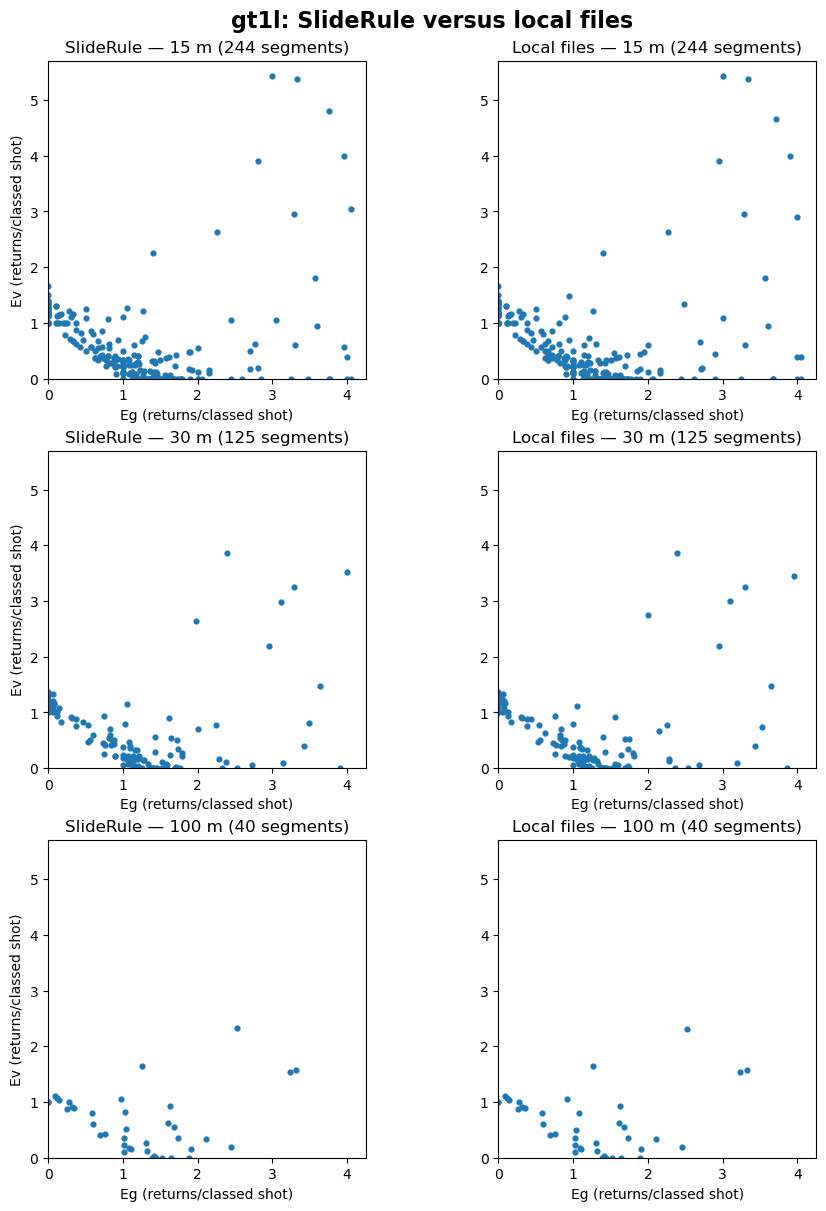

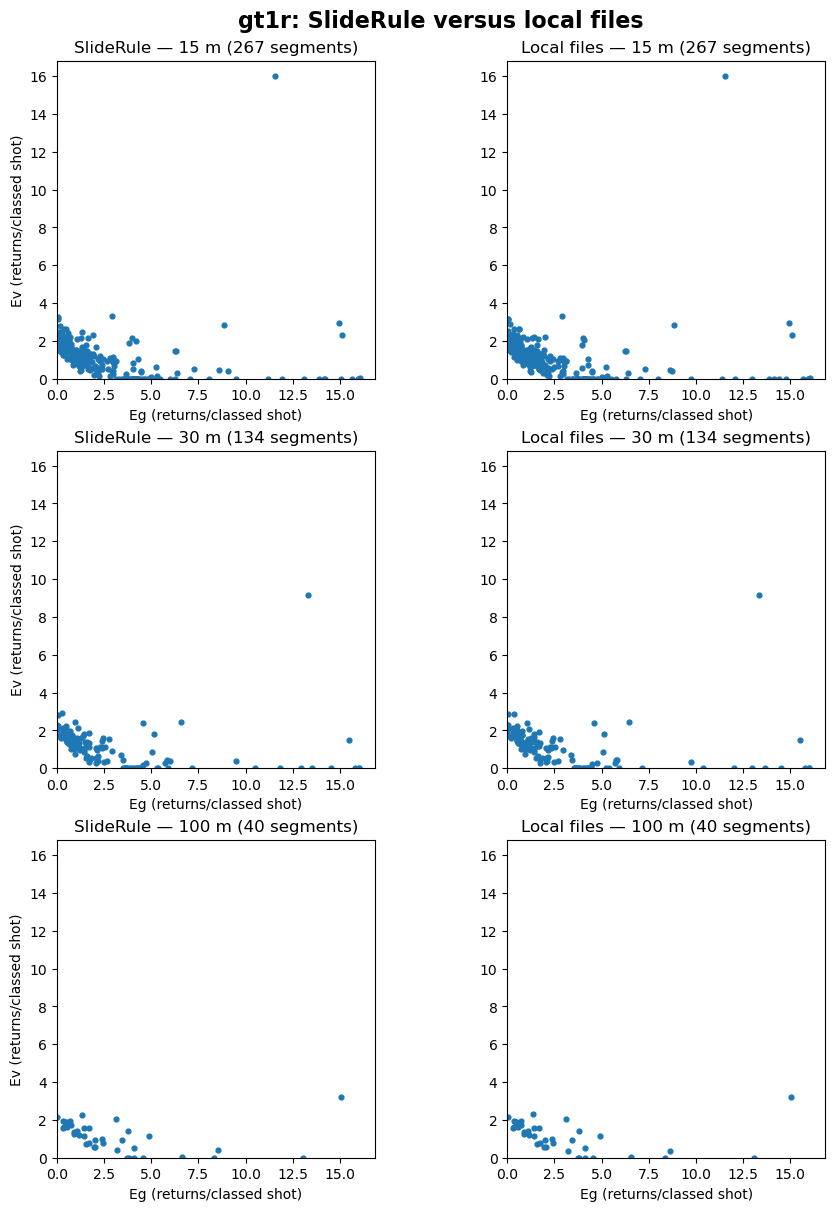

In [17]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Apply the same spatial and edge-bin filtering to both sources.
plot_sources = {}

for label, table in [
    ("SlideRule", segments),
    ("Local files", local_segments),
]:
    table = table.copy()
    table["in_analysis_roi"] = inside_roi(table)
    table = table[
        table.in_analysis_roi & ~table.edge_bin
    ].copy()

    valid = np.isfinite(
        table[["photon_rate_te", "photon_rate_can_nr"]]
    ).all(axis=1)
    plot_sources[label] = table[valid]

for beam in BEAMS:
    beam_sources = {
        label: table[
            (table.beam == beam) & table.length_m.isin(LENGTHS)
        ]
        for label, table in plot_sources.items()
    }
    combined = pd.concat(beam_sources.values(), ignore_index=True)

    if combined.empty:
        print(f"No data to plot for {beam}.")
        continue

    # Same limits for every resolution and both sources within this beam.
    xmax = max(combined.photon_rate_te.max() * 1.05, 0.1)
    ymax = max(combined.photon_rate_can_nr.max() * 1.05, 0.1)

    fig, axes = plt.subplots(
        len(LENGTHS), 2,
        figsize=(9, 4 * len(LENGTHS)),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    fig.suptitle(
        f"{beam}: SlideRule versus local files",
        fontsize=16,
        fontweight="bold",
    )

    for i, length in enumerate(LENGTHS):
        for j, (label, table) in enumerate(beam_sources.items()):
            t = table[table.length_m == length]
            ax = axes[i, j]

            ax.scatter(
                t.photon_rate_te,
                t.photon_rate_can_nr,
                color="tab:blue",
                s=12,
            )
            ax.set(
                title=f"{label} — {length} m ({len(t)} segments)",
                xlabel="Eg (returns/classed shot)",
                xlim=(0, xmax),
                ylim=(0, ymax),
            )
            if j == 0:
                ax.set_ylabel("Ev (returns/classed shot)")

            ax.set_box_aspect(1)
            ax.tick_params(labelbottom=True, labelleft=True)

    plt.show()

### Compare with your corrected PhoREAL rebinner

In your existing environment, pass the same trimmed atl03.df and atl08.df to legacy_rebin(...) and your original rebin_atl08(...). Match on h_ind (original) versus bin_id (new), with a separate comparison per beam and resolution. This tests the aggregation without changing your at_step boundaries. Example:

In [22]:
import sys
from pathlib import Path
from copy import deepcopy

# Relative to the notebook's working directory; adjust if needed.
PHOREAL_PATH = Path("../../src/PhoREAL").resolve()

print("PhoREAL path:", PHOREAL_PATH)
if not (PHOREAL_PATH / "phoreal" / "reader.py").is_file():
    raise FileNotFoundError(
        "Adjust PHOREAL_PATH to the folder containing the phoreal package."
    )

sys.path.insert(0, str(PHOREAL_PATH))

from phoreal.reader import get_atl03_struct, get_atl08_struct
from phoreal.binner import rebin_atl08
from shapely.geometry import Polygon
from shapely import contains_xy

import phoreal.reader
import phoreal.binner
print("Reader:", phoreal.reader.__file__)
print("Rebinner:", phoreal.binner.__file__)

gt = BEAMS[0]  # Change to another beam if needed.
length = 30

# Load your existing local files through the original PhoREAL reader.
phoreal_atl03 = get_atl03_struct(
    str(LOCAL_ATL03), gt, str(LOCAL_ATL08)
)
phoreal_atl08 = get_atl08_struct(
    str(LOCAL_ATL08), gt, phoreal_atl03
)

# Apply the same buffered spatial extent used for the photon retrieval.
shape = Polygon([(p["lon"], p["lat"]) for p in polygon])

for obj, lon_col, lat_col in [
    (phoreal_atl03, "lon_ph", "lat_ph"),
    (phoreal_atl08, "longitude", "latitude"),
]:
    mask = contains_xy(
        shape,
        obj.df[lon_col].to_numpy(),
        obj.df[lat_col].to_numpy(),
    )
    obj.df = obj.df.loc[mask].copy()

print(
    f"{gt}: {len(phoreal_atl03.df)} photons, "
    f"{len(phoreal_atl08.df)} ATL08 segments"
)

legacy = legacy_rebin(
    phoreal_atl03.df, phoreal_atl08.df, length,
    RESOURCE, gt, res_field="alongtrack",
)
original = rebin_atl08(
    deepcopy(phoreal_atl03),
    deepcopy(phoreal_atl08),
    gt, length, "alongtrack",
)

check = original.merge(
    legacy,
    left_on="h_ind",
    right_on="bin_id",
    suffixes=("_old", "_new"),
    how="outer",
    indicator=True,
    validate="one_to_one",
)
print("Bin membership:", check._merge.value_counts().to_dict())

shared = check[check._merge == "both"]
report = []

for col in [
    "n_te_photons", "n_ca_photons", "n_toc_photons",
    "n_classed_shots", "photon_rate_te", "photon_rate_can_nr",
]:
    old = shared[col + "_old"]
    new = shared[col + "_new"]
    valid = np.isfinite(old) & np.isfinite(new)
    difference = (old[valid] - new[valid]).abs()

    report.append({
        "field": col,
        "compared": int(valid.sum()),
        "finite_in_only_one": int(
            (np.isfinite(old) != np.isfinite(new)).sum()
        ),
        "mean_absolute_difference": difference.mean(),
        "max_absolute_difference": difference.max(),
    })

display(pd.DataFrame(report))

PhoREAL path: /home/s1803229/src/PhoREAL
Reader: /home/s1803229/src/PhoREAL/phoreal/reader.py
Rebinner: /home/s1803229/src/PhoREAL/phoreal/binner.py
gt1l: 13645 photons, 45 ATL08 segments
Bin membership: {'both': 308, 'left_only': 0, 'right_only': 0}


,field,compared,finite_in_only_one,mean_absolute_difference,max_absolute_difference
0,n_te_photons,232,76,0.0,0.0
1,n_ca_photons,209,99,0.0,0.0
2,n_toc_photons,131,177,0.0,0.0
3,n_classed_shots,281,27,0.0,0.0
4,photon_rate_te,232,49,0.0,0.0
5,photon_rate_can_nr,116,165,0.0,0.0


Inspect missing values separately: the new implementation deliberately records absent classes as zero. Comparing native-distance bins directly with legacy bin IDs is not a valid numerical equivalence test. Use the legacy adapter above first; then inspect how changing the coordinate changes membership.

The supplied current script only applies at_step when there are more than two ATL08 rows. The adapter preserves that detail. Duplicate coordinates (zero step) are rejected. Real gaps without an adjacent pair can still invalidate the minimum-spacing assumption, as your email already acknowledges.